# Switch Transformer: Scaling to Trillion Parameter Models with Simple and Efficient Sparsity**Paper:** Fedus, Zoph, Shazeer (2021) — JMLR  **arXiv:** [2101.03961](https://arxiv.org/abs/2101.03961)This notebook implements a simplified Switch Transformer that replaces the standard FFN in a Transformer encoder with a **Mixture-of-Experts (MoE) layer using top-1 (switch) routing**. We compare it against a standard dense Transformer on training speed, parameter efficiency, and expert utilization.

## 1. Imports and Configuration

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import time
import matplotlib.pyplot as plt
import numpy as np

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# Hyperparameters
D_MODEL = 128          # embedding dimension
NUM_HEADS = 4          # attention heads
D_FF = 512             # FFN hidden dimension
NUM_EXPERTS = 8        # number of experts in Switch MoE
NUM_LAYERS = 2         # transformer encoder layers
VOCAB_SIZE = 1000      # token vocabulary
SEQ_LEN = 64           # sequence length
BATCH_SIZE = 64        # batch size
NUM_CLASSES = 10       # classification classes
EPOCHS = 20            # training epochs
LR = 1e-3              # learning rate
CAPACITY_FACTOR = 1.25 # expert capacity factor
AUX_LOSS_WEIGHT = 0.01 # load balancing loss weight
Z_LOSS_WEIGHT = 0.001  # router z-loss weight

Device: cuda


## 2. Toy Dataset: Synthetic Token Sequence ClassificationWe create a synthetic task where token sequences must be classified into one of `NUM_CLASSES` categories. The label is determined by a rule based on token statistics (sum of tokens mod num_classes), ensuring the task is learnable but requires the model to attend to all tokens.

In [2]:
class SyntheticSequenceDataset(torch.utils.data.Dataset):
    """Generates synthetic token sequences with rule-based labels."""
    def __init__(self, num_samples=5000, vocab_size=VOCAB_SIZE, seq_len=SEQ_LEN, num_classes=NUM_CLASSES):
        self.data = torch.randint(0, vocab_size, (num_samples, seq_len))
        # Label = (sum of tokens + positional weighting) mod num_classes
        # This creates a non-trivial classification task
        weights = torch.arange(1, seq_len + 1, dtype=torch.float)  # positional weights
        weighted_sums = (self.data.float() * weights.unsqueeze(0)).sum(dim=1)
        self.labels = (weighted_sums.long()) % num_classes

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

# Create datasets
train_dataset = SyntheticSequenceDataset(num_samples=4000)
val_dataset = SyntheticSequenceDataset(num_samples=1000)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}")
print(f"Sample batch shape: {next(iter(train_loader))[0].shape}")
print(f"Label distribution: {torch.bincount(train_dataset.labels, minlength=NUM_CLASSES)}")

Train samples: 4000, Val samples: 1000
Sample batch shape: torch.Size([64, 64])


Label distribution: tensor([398, 380, 426, 413, 377, 412, 392, 398, 397, 407])


## 3. Dense FFN Module (Baseline)

In [3]:
class DenseFFN(nn.Module):
    """Standard Transformer FFN: Linear -> GELU -> Linear with residual."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.w2 = nn.Linear(d_ff, d_model)
        self.act = nn.GELU()

    def forward(self, x):
        # x: (batch, seq, d_model)
        return self.w2(self.act(self.w1(x)))

## 4. Switch RouterThe router is a single linear layer that maps each token's hidden state to `num_experts` logits. A softmax converts these to probabilities, and we pick the top-1 expert via `argmax`. The router also computes the auxiliary load-balancing loss and z-loss for training stability.

In [4]:
class SwitchRouter(nn.Module):
    """Routes each token to a single expert (top-1 routing)."""
    def __init__(self, d_model, num_experts):
        super().__init__()
        self.num_experts = num_experts
        self.router = nn.Linear(d_model, num_experts, bias=False)

    def forward(self, x):
        # x: (batch, seq, d_model)
        # Router logits
        logits = self.router(x)  # (batch, seq, num_experts)

        # Router z-loss: penalize large logits for stability
        z_loss = torch.mean(torch.sum(torch.exp(logits), dim=-1))

        # Softmax probabilities
        probs = F.softmax(logits, dim=-1)  # (batch, seq, num_experts)

        # Top-1 expert selection
        expert_idx = torch.argmax(probs, dim=-1)  # (batch, seq)

        return expert_idx, probs, z_loss

## 5. Switch MoE Layer (Core)This is the heart of the Switch Transformer. It contains `num_experts` independent FFN modules and routes each token to exactly one expert. Key steps:1. Router determines which expert each token goes to.2. Tokens are gathered per-expert (with capacity factor to limit memory).3. Each expert processes its assigned tokens.4. Outputs are scattered back to original positions.5. Load-balancing auxiliary loss is computed.

In [5]:
class SwitchMoELayer(nn.Module):
    """Mixture-of-Experts layer with top-1 (switch) routing."""
    def __init__(self, d_model, d_ff, num_experts, capacity_factor=1.25,
                 aux_loss_weight=0.01, z_loss_weight=0.001):
        super().__init__()
        self.num_experts = num_experts
        self.capacity_factor = capacity_factor
        self.aux_loss_weight = aux_loss_weight
        self.z_loss_weight = z_loss_weight

        self.router = SwitchRouter(d_model, num_experts)
        self.experts = nn.ModuleList([
            DenseFFN(d_model, d_ff) for _ in range(num_experts)
        ])

    def forward(self, x):
        # x: (batch, seq, d_model)
        batch_size, seq_len, d_model = x.shape

        # Route tokens
        expert_idx, router_probs, z_loss = self.router(x)  # (B,S), (B,S,E), scalar

        # Expert capacity
        total_tokens = batch_size * seq_len
        expert_capacity = int(math.ceil(total_tokens / self.num_experts * self.capacity_factor))
        expert_capacity = max(expert_capacity, 1)

        # Flatten for easier indexing
        flat_x = x.reshape(-1, d_model)           # (B*S, D)
        flat_idx = expert_idx.reshape(-1)          # (B*S,)
        flat_probs = router_probs.reshape(-1, self.num_experts)  # (B*S, E)

        # Gather router probability for selected expert
        selected_probs = flat_probs.gather(1, flat_idx.unsqueeze(1)).squeeze(1)  # (B*S,)

        # Process each expert
        output = torch.zeros_like(flat_x)  # (B*S, D)
        aux_loss = torch.tensor(0.0, device=x.device)

        # Count tokens per expert for load balancing
        tokens_per_expert = torch.zeros(self.num_experts, device=x.device)
        expert_outputs_list = []

        for i in range(self.num_experts):
            # Find tokens routed to expert i
            mask = (flat_idx == i)
            num_tokens = mask.sum().item()
            tokens_per_expert[i] = num_tokens

            if num_tokens > 0:
                expert_input = flat_x[mask]  # (num_tokens, D)

                # Apply capacity limit
                if num_tokens > expert_capacity:
                    # Only process first expert_capacity tokens
                    expert_input = expert_input[:expert_capacity]
                    # Scale probabilities for dropped tokens remain as residual
                    expert_probs = selected_probs[mask][:expert_capacity]
                else:
                    expert_probs = selected_probs[mask]

                # Expert FFN
                expert_output = self.experts[i](expert_input)  # (num_tokens, D)

                # Scale by router probability (for differentiability)
                expert_output = expert_output * expert_probs.unsqueeze(1)

                # Place outputs back
                indices = mask.nonzero(as_tuple=True)[0]
                if num_tokens > expert_capacity:
                    indices = indices[:expert_capacity]

                output[indices] = expert_output

        # Load balancing auxiliary loss
        # f_i = fraction of tokens routed to expert i
        # P_i = average router probability for expert i
        f = tokens_per_expert / total_tokens  # (E,)
        P = router_probs.reshape(-1, self.num_experts).mean(dim=0)  # (E,)
        aux_loss = self.num_experts * torch.sum(f * P)

        # Reshape back
        output = output.reshape(batch_size, seq_len, d_model)

        return output, self.aux_loss_weight * aux_loss + self.z_loss_weight * z_loss

## 6. Transformer Encoder Layer

In [6]:
class TransformerEncoderLayer(nn.Module):
    """Transformer encoder layer with either dense FFN or Switch MoE."""
    def __init__(self, d_model, num_heads, d_ff, num_experts=None, use_moe=False,
                 capacity_factor=1.25, dropout=0.1):
        super().__init__()
        self.use_moe = use_moe

        # Multi-head self-attention
        self.attention = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

        # FFN: either dense or Switch MoE
        if use_moe:
            self.ffn = SwitchMoELayer(d_model, d_ff, num_experts, capacity_factor=capacity_factor)
        else:
            self.ffn = DenseFFN(d_model, d_ff)

    def forward(self, x):
        # Self-attention with residual
        attn_out, _ = self.attention(x, x, x, need_weights=False)
        x = self.norm1(x + self.dropout(attn_out))

        # FFN with residual
        if self.use_moe:
            ffn_out, aux_loss = self.ffn(x)
            x = self.norm2(x + self.dropout(ffn_out))
            return x, aux_loss
        else:
            ffn_out = self.ffn(x)
            x = self.norm2(x + self.dropout(ffn_out))
            return x, torch.tensor(0.0, device=x.device)

## 7. Model Assembly

In [7]:
class SwitchTransformer(nn.Module):
    """Full Switch Transformer for sequence classification."""
    def __init__(self, vocab_size, d_model, num_heads, d_ff, num_experts,
                 num_layers, num_classes, capacity_factor=1.25, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = nn.Parameter(torch.randn(1, SEQ_LEN, d_model) * 0.02)

        self.layers = nn.ModuleList([
            TransformerEncoderLayer(d_model, num_heads, d_ff, num_experts,
                                    use_moe=True, capacity_factor=capacity_factor,
                                    dropout=dropout)
            for _ in range(num_layers)
        ])

        self.classifier = nn.Linear(d_model, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (batch, seq) token IDs
        x = self.embedding(x) + self.pos_encoding  # (batch, seq, d_model)

        total_aux_loss = torch.tensor(0.0, device=x.device)
        for layer in self.layers:
            x, aux_loss = layer(x)
            total_aux_loss = total_aux_loss + aux_loss

        # Mean pooling over sequence
        x = x.mean(dim=1)  # (batch, d_model)
        x = self.dropout(x)
        logits = self.classifier(x)  # (batch, num_classes)

        return logits, total_aux_loss


class DenseTransformer(nn.Module):
    """Dense Transformer baseline (same architecture, no MoE)."""
    def __init__(self, vocab_size, d_model, num_heads, d_ff,
                 num_layers, num_classes, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = nn.Parameter(torch.randn(1, SEQ_LEN, d_model) * 0.02)

        self.layers = nn.ModuleList([
            TransformerEncoderLayer(d_model, num_heads, d_ff,
                                    use_moe=False, dropout=dropout)
            for _ in range(num_layers)
        ])

        self.classifier = nn.Linear(d_model, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.embedding(x) + self.pos_encoding

        for layer in self.layers:
            x, _ = layer(x)

        x = x.mean(dim=1)
        x = self.dropout(x)
        logits = self.classifier(x)

        return logits, torch.tensor(0.0, device=x.device)

## 8. Instantiate Models and Compare Parameters

In [8]:
# Build models
switch_model = SwitchTransformer(
    vocab_size=VOCAB_SIZE, d_model=D_MODEL, num_heads=NUM_HEADS,
    d_ff=D_FF, num_experts=NUM_EXPERTS, num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES, capacity_factor=CAPACITY_FACTOR
).to(device)

dense_model = DenseTransformer(
    vocab_size=VOCAB_SIZE, d_model=D_MODEL, num_heads=NUM_HEADS,
    d_ff=D_FF, num_layers=NUM_LAYERS, num_classes=NUM_CLASSES
).to(device)

# Count parameters
switch_params = sum(p.numel() for p in switch_model.parameters())
dense_params = sum(p.numel() for p in dense_model.parameters())

print(f"Switch Transformer parameters: {switch_params:,}")
print(f"Dense Transformer parameters:   {dense_params:,}")
print(f"Parameter ratio (Switch/Dense): {switch_params / dense_params:.2f}x")
print()

# Breakdown
switch_expert_params = sum(p.numel() for layer in switch_model.layers
                          for p in layer.ffn.experts.parameters())
dense_ffn_params = sum(p.numel() for layer in dense_model.layers
                       for p in layer.ffn.parameters())
print(f"Switch expert FFN params: {switch_expert_params:,} ({NUM_EXPERTS} experts)")
print(f"Dense FFN params:         {dense_ffn_params:,}")
print(f"Expert param ratio:       {switch_expert_params / dense_ffn_params:.2f}x")

Switch Transformer parameters: 2,380,042
Dense Transformer parameters:   534,026
Parameter ratio (Switch/Dense): 4.46x

Switch expert FFN params: 2,107,392 (8 experts)
Dense FFN params:         263,424
Expert param ratio:       8.00x


## 9. Training Loop

In [9]:
def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LR, model_name="Model"):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    train_losses = []
    val_accs = []
    epoch_times = []

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        epoch_start = time.time()

        for batch_idx, (tokens, labels) in enumerate(train_loader):
            tokens, labels = tokens.to(device), labels.to(device)

            optimizer.zero_grad()
            logits, aux_loss = model(tokens)
            task_loss = F.cross_entropy(logits, labels)
            total_loss = task_loss + aux_loss
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss += total_loss.item()

        scheduler.step()
        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)
        avg_loss = epoch_loss / len(train_loader)
        train_losses.append(avg_loss)

        # Validation
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for tokens, labels in val_loader:
                tokens, labels = tokens.to(device), labels.to(device)
                logits, _ = model(tokens)
                preds = logits.argmax(dim=-1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        val_acc = correct / total
        val_accs.append(val_acc)

        print(f"[{model_name}] Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | "
              f"Val Acc: {val_acc:.4f} | Time: {epoch_time:.2f}s")

    return {
        'train_losses': train_losses,
        'val_accs': val_accs,
        'epoch_times': epoch_times,
        'total_time': sum(epoch_times),
        'final_acc': val_accs[-1],
        'params': sum(p.numel() for p in model.parameters())
    }

In [10]:
# Train Dense baseline
print("=" * 60)
print("Training Dense Transformer (Baseline)")
print("=" * 60)
dense_results = train_model(dense_model, train_loader, val_loader,
                            epochs=EPOCHS, lr=LR, model_name="Dense")

Training Dense Transformer (Baseline)


[Dense] Epoch 1/20 | Loss: 2.3258 | Val Acc: 0.1070 | Time: 1.77s


[Dense] Epoch 2/20 | Loss: 2.2860 | Val Acc: 0.0840 | Time: 0.50s


[Dense] Epoch 3/20 | Loss: 2.2471 | Val Acc: 0.0840 | Time: 0.51s


[Dense] Epoch 4/20 | Loss: 2.1824 | Val Acc: 0.0790 | Time: 0.51s


...

[Dense] Epoch 16/20 | Loss: 0.1907 | Val Acc: 0.1030 | Time: 0.51s


[Dense] Epoch 17/20 | Loss: 0.1655 | Val Acc: 0.1040 | Time: 0.53s


[Dense] Epoch 18/20 | Loss: 0.1491 | Val Acc: 0.1050 | Time: 0.52s


[Dense] Epoch 19/20 | Loss: 0.1307 | Val Acc: 0.1060 | Time: 0.53s


[Dense] Epoch 20/20 | Loss: 0.1245 | Val Acc: 0.1070 | Time: 0.54s


In [11]:
# Train Switch Transformer
print("\n" + "=" * 60)
print("Training Switch Transformer (MoE)")
print("=" * 60)
# Re-seed for fair comparison
torch.manual_seed(42)
switch_results = train_model(switch_model, train_loader, val_loader,
                             epochs=EPOCHS, lr=LR, model_name="Switch")


Training Switch Transformer (MoE)


[Switch] Epoch 1/20 | Loss: 2.3492 | Val Acc: 0.0960 | Time: 2.51s


[Switch] Epoch 2/20 | Loss: 2.2955 | Val Acc: 0.1010 | Time: 2.11s


[Switch] Epoch 3/20 | Loss: 2.2167 | Val Acc: 0.0860 | Time: 2.03s


[Switch] Epoch 4/20 | Loss: 2.0777 | Val Acc: 0.0960 | Time: 2.03s


...

[Switch] Epoch 16/20 | Loss: 0.0847 | Val Acc: 0.0980 | Time: 2.01s


[Switch] Epoch 17/20 | Loss: 0.0762 | Val Acc: 0.0960 | Time: 2.02s


[Switch] Epoch 18/20 | Loss: 0.0742 | Val Acc: 0.0950 | Time: 1.97s


[Switch] Epoch 19/20 | Loss: 0.0703 | Val Acc: 0.0960 | Time: 1.99s


[Switch] Epoch 20/20 | Loss: 0.0688 | Val Acc: 0.0930 | Time: 2.00s


## 10. Results: Comparison Plots

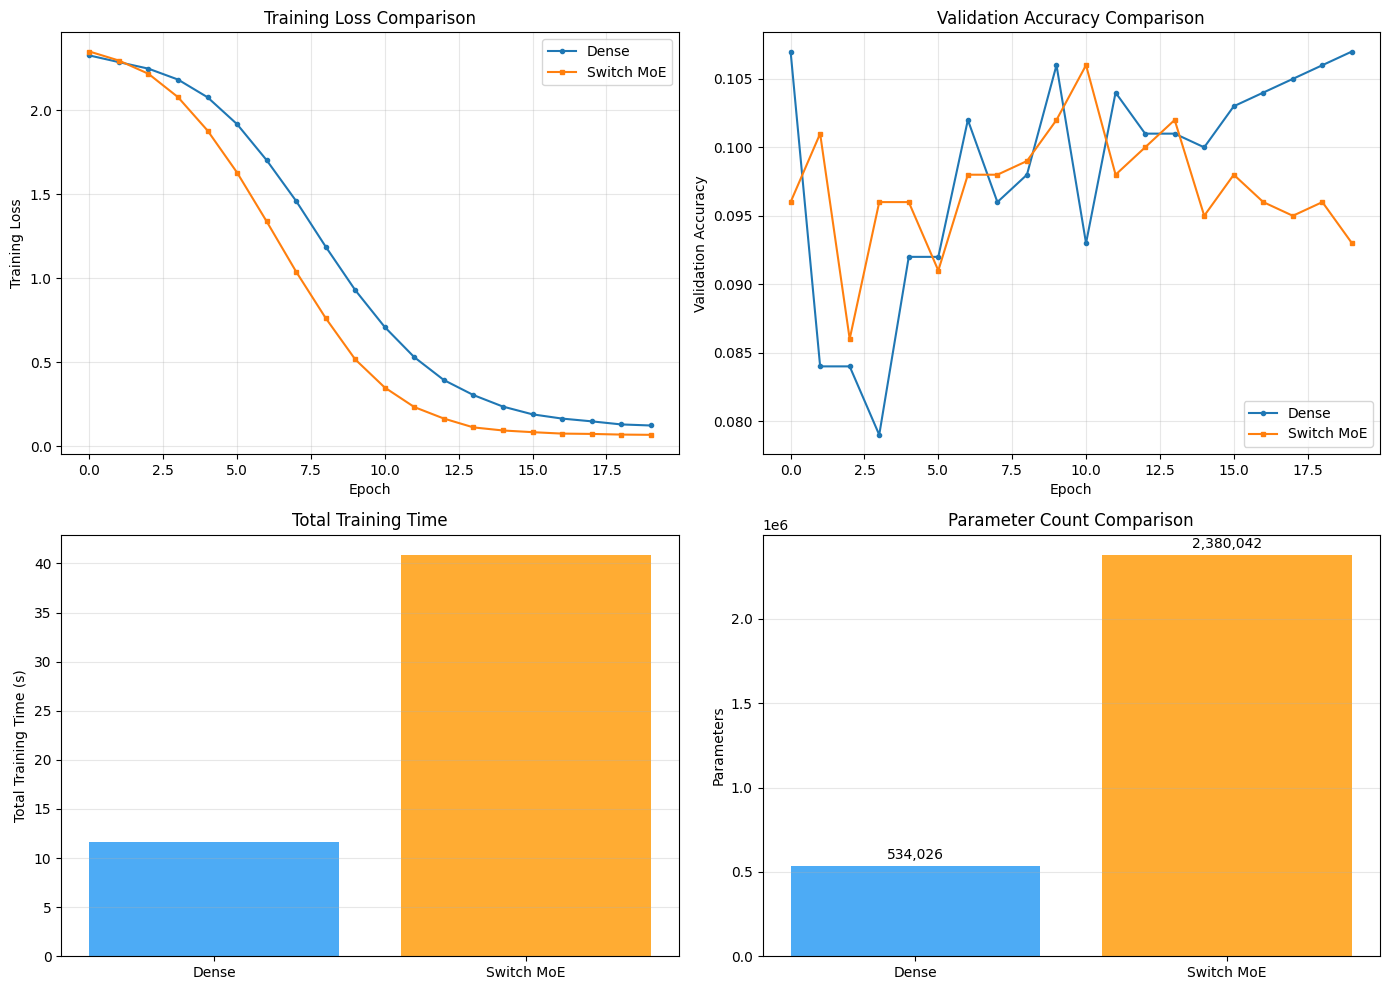

Comparison plot saved.


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Training Loss
axes[0, 0].plot(dense_results['train_losses'], label='Dense', marker='o', markersize=3)
axes[0, 0].plot(switch_results['train_losses'], label='Switch MoE', marker='s', markersize=3)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Training Loss')
axes[0, 0].set_title('Training Loss Comparison')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Validation Accuracy
axes[0, 1].plot(dense_results['val_accs'], label='Dense', marker='o', markersize=3)
axes[0, 1].plot(switch_results['val_accs'], label='Switch MoE', marker='s', markersize=3)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Validation Accuracy')
axes[0, 1].set_title('Validation Accuracy Comparison')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Epoch Time
axes[1, 0].bar(['Dense', 'Switch MoE'], [dense_results['total_time'], switch_results['total_time']],
               color=['#2196F3', '#FF9800'], alpha=0.8)
axes[1, 0].set_ylabel('Total Training Time (s)')
axes[1, 0].set_title('Total Training Time')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Parameter Count
axes[1, 1].bar(['Dense', 'Switch MoE'], [dense_results['params'], switch_results['params']],
               color=['#2196F3', '#FF9800'], alpha=0.8)
axes[1, 1].set_ylabel('Parameters')
axes[1, 1].set_title('Parameter Count Comparison')
axes[1, 1].grid(True, alpha=0.3, axis='y')
# Add value labels
for ax in [axes[1, 1]]:
    for i, v in enumerate([dense_results['params'], switch_results['params']]):
        ax.text(i, v + max(dense_results['params'], switch_results['params']) * 0.01,
                f'{v:,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('switch_vs_dense_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Comparison plot saved.")

## 11. Summary Table

In [13]:
print(f"{'Metric':<25} {'Dense':>15} {'Switch MoE':>15} {'Ratio':>10}")
print("=" * 65)
print(f"{'Parameters':<25} {dense_results['params']:>15,} {switch_results['params']:>15,} {switch_results['params']/dense_results['params']:>9.2f}x")
print(f"{'Final Val Accuracy':<25} {dense_results['final_acc']:>15.4f} {switch_results['final_acc']:>15.4f} {switch_results['final_acc']/dense_results['final_acc']:>9.2f}x")
print(f"{'Total Training Time (s)':<25} {dense_results['total_time']:>15.2f} {switch_results['total_time']:>15.2f} {switch_results['total_time']/dense_results['total_time']:>9.2f}x")
print(f"{'Avg Time/Epoch (s)':<25} {np.mean(dense_results['epoch_times']):>15.2f} {np.mean(switch_results['epoch_times']):>15.2f} {np.mean(switch_results['epoch_times'])/np.mean(dense_results['epoch_times']):>9.2f}x")
print()
print("Key observations:")
print(f"  - Switch model has {switch_results['params']/dense_results['params']:.1f}x more parameters but similar FLOPs per token")
print(f"  - Switch model uses {NUM_EXPERTS} experts, each token routed to exactly 1 expert (top-1)")
print(f"  - The parameter increase comes from having {NUM_EXPERTS} independent FFN modules")

Metric                              Dense      Switch MoE      Ratio
Parameters                        534,026       2,380,042      4.46x
Final Val Accuracy                 0.1070          0.0930      0.87x
Total Training Time (s)             11.61           40.89      3.52x
Avg Time/Epoch (s)                   0.58            2.04      3.52x

Key observations:
  - Switch model has 4.5x more parameters but similar FLOPs per token
  - Switch model uses 8 experts, each token routed to exactly 1 expert (top-1)
  - The parameter increase comes from having 8 independent FFN modules


## 12. Expert Routing Visualization

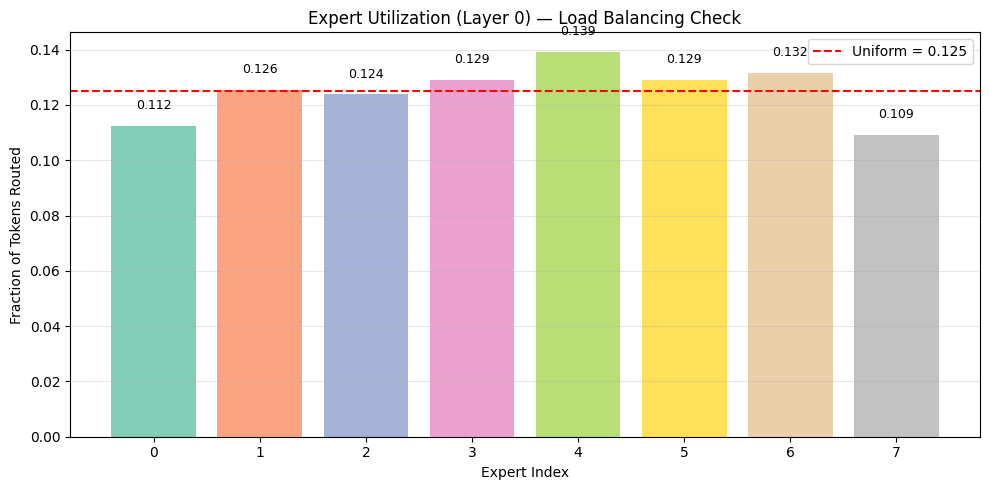


Expert utilization (should be close to 0.125 for balanced):
  Expert 0: 0.1125 (7198 tokens)
  Expert 1: 0.1255 (8034 tokens)
  Expert 2: 0.1238 (7925 tokens)
  Expert 3: 0.1291 (8263 tokens)
  Expert 4: 0.1393 (8915 tokens)
  Expert 5: 0.1291 (8261 tokens)
  Expert 6: 0.1315 (8417 tokens)
  Expert 7: 0.1092 (6987 tokens)
  Total tokens: 64000
  Standard deviation: 0.0099 (lower = more balanced)


In [14]:
# Analyze expert utilization on validation data
switch_model.eval()
expert_counts = torch.zeros(NUM_EXPERTS, device=device)
total_tokens_seen = 0

with torch.no_grad():
    for tokens, labels in val_loader:
        tokens = tokens.to(device)
        # Get embeddings
        x = switch_model.embedding(tokens) + switch_model.pos_encoding
        # Pass through first layer to get routing
        x = switch_model.layers[0](switch_model.norm1(x))[0] if False else x
        # Actually we need to trace through the layer properly
        # Let's directly access the router of the first layer
        layer = switch_model.layers[0]
        x = layer.embedding_output if hasattr(layer, 'embedding_output') else x
        # Forward through attention first
        attn_out, _ = layer.attention(x, x, x, need_weights=False)
        x = layer.norm1(x + attn_out)
        # Now route
        expert_idx, probs, _ = layer.ffn.router(x)
        for i in range(NUM_EXPERTS):
            expert_counts[i] += (expert_idx == i).sum().item()
        total_tokens_seen += expert_idx.numel()

expert_fractions = expert_counts / total_tokens_seen

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(range(NUM_EXPERTS), expert_fractions.cpu().numpy(),
              color=plt.cm.Set2(np.linspace(0, 1, NUM_EXPERTS)), alpha=0.8)
ax.axhline(y=1.0/NUM_EXPERTS, color='red', linestyle='--', label=f'Uniform = {1/NUM_EXPERTS:.3f}')
ax.set_xlabel('Expert Index')
ax.set_ylabel('Fraction of Tokens Routed')
ax.set_title('Expert Utilization (Layer 0) — Load Balancing Check')
ax.set_xticks(range(NUM_EXPERTS))
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# Add value labels
for bar, frac in zip(bars, expert_fractions.cpu().numpy()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{frac:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('expert_utilization.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nExpert utilization (should be close to {1/NUM_EXPERTS:.3f} for balanced):")
for i, frac in enumerate(expert_fractions.cpu().numpy()):
    print(f"  Expert {i}: {frac:.4f} ({expert_counts[i].int().item()} tokens)")
print(f"  Total tokens: {total_tokens_seen}")
print(f"  Standard deviation: {expert_fractions.std().item():.4f} (lower = more balanced)")

## 13. Router Probability Heatmap (Sample Batch)

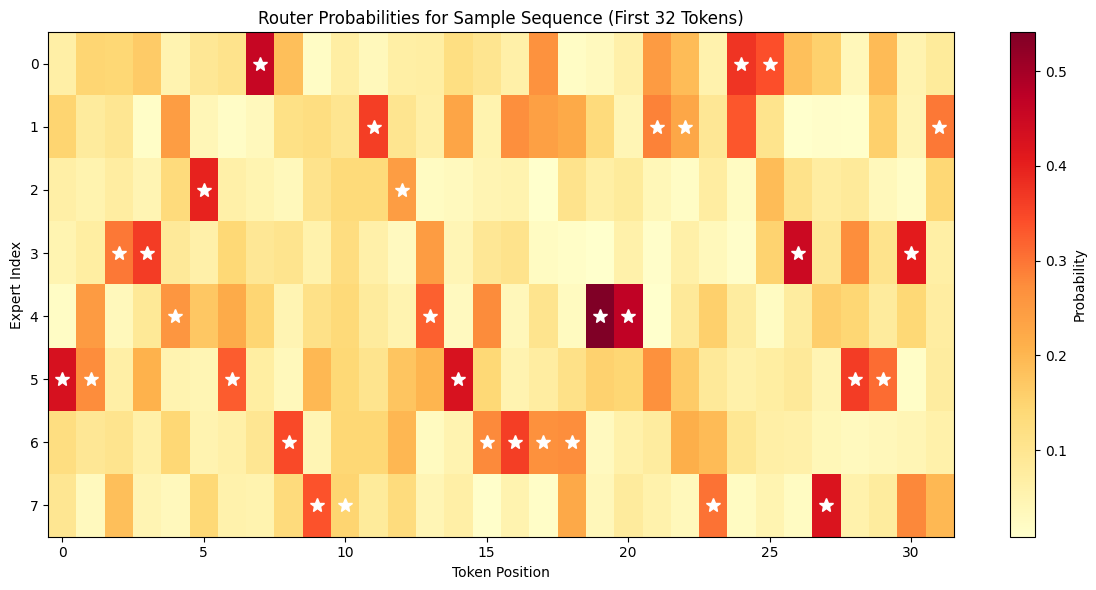

Selected experts for first 32 tokens: [5 5 3 3 4 2 5 0 6 7 7 1 2 4 5 6 6 6 6 4 4 1 1 7 0 0 3 7 5 5 3 1]
Unique experts used: 8 out of 8


In [15]:
# Visualize router probabilities for a sample batch
switch_model.eval()
with torch.no_grad():
    sample_tokens, _ = next(iter(val_loader))
    sample_tokens = sample_tokens.to(device)

    # Forward through embedding + first layer attention
    x = switch_model.embedding(sample_tokens) + switch_model.pos_encoding
    layer = switch_model.layers[0]
    attn_out, _ = layer.attention(x, x, x, need_weights=False)
    x = layer.norm1(x + attn_out)

    # Get router probabilities
    expert_idx, probs, _ = layer.ffn.router(x)

    # Plot heatmap for first 32 tokens of first sample
    sample_probs = probs[0, :32].cpu().numpy()  # (32, num_experts)

    fig, ax = plt.subplots(figsize=(12, 6))
    im = ax.imshow(sample_probs.T, aspect='auto', cmap='YlOrRd')
    ax.set_xlabel('Token Position')
    ax.set_ylabel('Expert Index')
    ax.set_title('Router Probabilities for Sample Sequence (First 32 Tokens)')
    ax.set_yticks(range(NUM_EXPERTS))
    plt.colorbar(im, label='Probability')

    # Mark selected expert
    selected = expert_idx[0, :32].cpu().numpy()
    for pos, exp in enumerate(selected):
        ax.plot(pos, exp, 'w*', markersize=10)

    plt.tight_layout()
    plt.savefig('router_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f"Selected experts for first 32 tokens: {selected}")
    print(f"Unique experts used: {len(np.unique(selected))} out of {NUM_EXPERTS}")

## 14. ConclusionsThis notebook demonstrated the core ideas of the Switch Transformer:1. **Top-1 (Switch) Routing**: Each token is routed to exactly one expert, simplifying the MoE routing compared to top-k approaches.2. **Parameter Efficiency**: The Switch model has more parameters (from multiple expert FFNs) but similar computation per token — only one expert processes each token.3. **Load Balancing**: The auxiliary loss `α·N·Σ(f_i·P_i)` encourages uniform expert usage, preventing collapse to a single expert.4. **Training Stability**: Router z-loss and gradient clipping help stabilize training with sparse routing.### Key Takeaways from the Paper- Switch routing (k=1) outperforms MoE routing (k=2) on both quality and speed- Up to **7× faster pre-training** than dense T5-Base at the same FLOP budget- Scaled to **1 trillion parameters** with 4× speedup over T5-XXL- Sparse model gains can be distilled into dense models, preserving ~30% of quality improvement- Published in JMLR (2022), 5000+ citations### Simplifications in This Notebook- Toy classification task (not language modeling on C4)- 8 experts at d_model=128 (vs. 128 experts at d_model=768)- Single device (no distributed all-to-all communication)- No bfloat16 mixed precision- No distillation of sparse → dense

In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
